In [1]:
pip install pyodbc

Note: you may need to restart the kernel to use updated packages.


In [276]:
import pyodbc

# Path to your .accdb file
db_path = r"C:\Users\secua\Documents\nicolas\accessity\EOD 2015-2016_abril 2017 1.accdb"
driver = "{Microsoft Access Driver (*.mdb, *.accdb)}"

conn_str = f"DRIVER={driver};DBQ={db_path};"
conn = pyodbc.connect(conn_str)
cursor = conn.cursor()

# List available tables
for table in cursor.tables(tableType="TABLE"):
  print(table.table_name)

codModoAgregado
codProposito
codTamFam
codTipoVehiculo
codTramoIngresoHogar
codTramoIngresoPersonal
codVehicHogar
DATA_ETAPAS
DATA_HOGAR
DATA_PERSONA
DATA_VEHICULOS
DATA_VIAJES
XLOC_HOG


In [277]:
# Query a specific table
cursor.execute("SELECT * FROM codModoAgregado")
for row in cursor.fetchall():
  print(row)

cursor.close()
conn.close()

(1, '1 Caminata')
(2, '2 No Caminata')
(3, '3 Transporte Privado')
(4, '4 Transporte Público')
(5, '5 Transporte Combinado')


In [4]:
pip install pyodbc sqlalchemy sqlalchemy-access pandas pywin32

Note: you may need to restart the kernel to use updated packages.


In [278]:
import pandas as pd
import sqlalchemy as sa

pd.set_option("display.max_columns", None)

db_path = r"C:\Users\secua\Documents\nicolas\accessity\EOD 2015-2016_abril 2017 1.accdb"
engine = sa.create_engine(
    f"access+pyodbc:///?odbc_connect=Driver={{Microsoft Access Driver (*.mdb, *.accdb)}};DBQ={db_path};"
)

# Read a table straight into a pandas DataFrame
df = pd.read_sql("SELECT * FROM DATA_VIAJES", engine)
df.head()

df = df[df.ModoAgregado == 3.0]

In [279]:
len(df)

15094

In [281]:
df.ModoAgregado.value_counts(dropna=False)

# (1, '1 Caminata')
# (2, '2 No Caminata')
# (3, '3 Transporte Privado')
# (4, '4 Transporte Público')
# (5, '5 Transporte Combinado')

ModoAgregado
3.0    15094
Name: count, dtype: int64

In [12]:
df.columns.tolist()

['Folio',
 'ordenpersona',
 'ordenviaje',
 'Proposito',
 'PropositoVC',
 'Proposito_e',
 'OrigenActividadComuna',
 'OrigenActividadCalle',
 'OrigenActividadNumero',
 'OrigenActividadInterCalle',
 'OrigenActividadHito',
 'LugarActividadComuna',
 'LugarActividadCalle',
 'LugarActividadNumero',
 'LugarActividadInterCalle',
 'LugarActividadHito',
 'ActividadEmpresa',
 'ModoEtapa1',
 'ModoEtapa2',
 'ModoEtapa3',
 'ModoEtapa4',
 'ModoEtapa5',
 'CuadrasCaminadasDespues',
 'MinutosCaminadosDespues',
 'HoraLlegadaHora',
 'HoraLlegadaMinuto',
 'HoraVolvioSalirHora',
 'HoraVolvioSalirMinuto',
 'Coord_OrigenViaje',
 'Zona_OrigenViaje',
 'Sector_OrigenViaje',
 'HoraSalida',
 'Coord_DestinoViaje',
 'Zona_DestinoViaje',
 'Sector_DestinoViaje',
 'HoraLlegada',
 'TiempoViaje',
 'Distancia',
 'Periodo',
 'NumeroEtapasViaje',
 'HoraMediaViaje',
 'ModoAgregado',
 'FactorCorreccion_TH',
 'FactorCorreccion_SE',
 'FactorExpansion',
 'Fexpansionv_DL',
 'Fexpansionv_FDS']

## Definir macrozonas

In [30]:
import osmnx as ox

def get_place(place_name):
    area_gdf = ox.geocode_to_gdf(place_name)
    return area_gdf
    area = area_gdf.geometry.union_all()
    area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")

coronel = get_place("Coronel, Chile")
lota = get_place("Lota, Chile")
san_pedro = get_place("San Pedro de la Paz, Chile")
hualpen = get_place("Hualpén, Chile")
talcahuano = get_place("Talcahuano, Chile")
concepcion = get_place("Concepción, Chile")
penco = get_place("Penco, Chile")
tome = get_place("Tomé, Chile")
chiguayante = get_place("Chiguayante, Chile")
hualqui = get_place("Hualqui, Chile")

In [34]:
import pandas as pd
import geopandas as gpd

macrozones = pd.DataFrame(columns=["id", "geometry"])

def add_macrozone(dfs, rec):
    dfs = dfs if isinstance(dfs, list) else [dfs]
    geom = pd.concat(dfs).geometry.union_all()
    current = pd.DataFrame({
        "id": [len(rec)],
        "geometry": [geom]
    })
    return pd.concat([rec, current])

macrozones = add_macrozone([coronel, lota], macrozones)
macrozones = add_macrozone(san_pedro, macrozones)
macrozones = add_macrozone(hualpen, macrozones)
macrozones = add_macrozone(talcahuano, macrozones)
macrozones = add_macrozone(concepcion, macrozones)
macrozones = add_macrozone([penco, tome], macrozones)
macrozones = add_macrozone([chiguayante, hualqui], macrozones)

macrozones = gpd.GeoDataFrame(macrozones, geometry="geometry", crs=4326)
macrozones

,id,geometry
0,0,"MULTIPOLYGON (((-73.18459 -37.15237, -73.18431..."
0,1,"POLYGON ((-73.17 -36.81508, -73.16701 -36.8165..."
0,2,"MULTIPOLYGON (((-73.21744 -36.78821, -73.2174 ..."
0,3,"MULTIPOLYGON (((-73.15712 -36.7206, -73.15712 ..."
0,4,"POLYGON ((-73.09159 -36.82363, -73.08786 -36.8..."
0,5,"POLYGON ((-72.85135 -36.7483, -72.85153 -36.74..."
0,6,"POLYGON ((-72.94115 -36.9033, -72.94111 -36.90..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

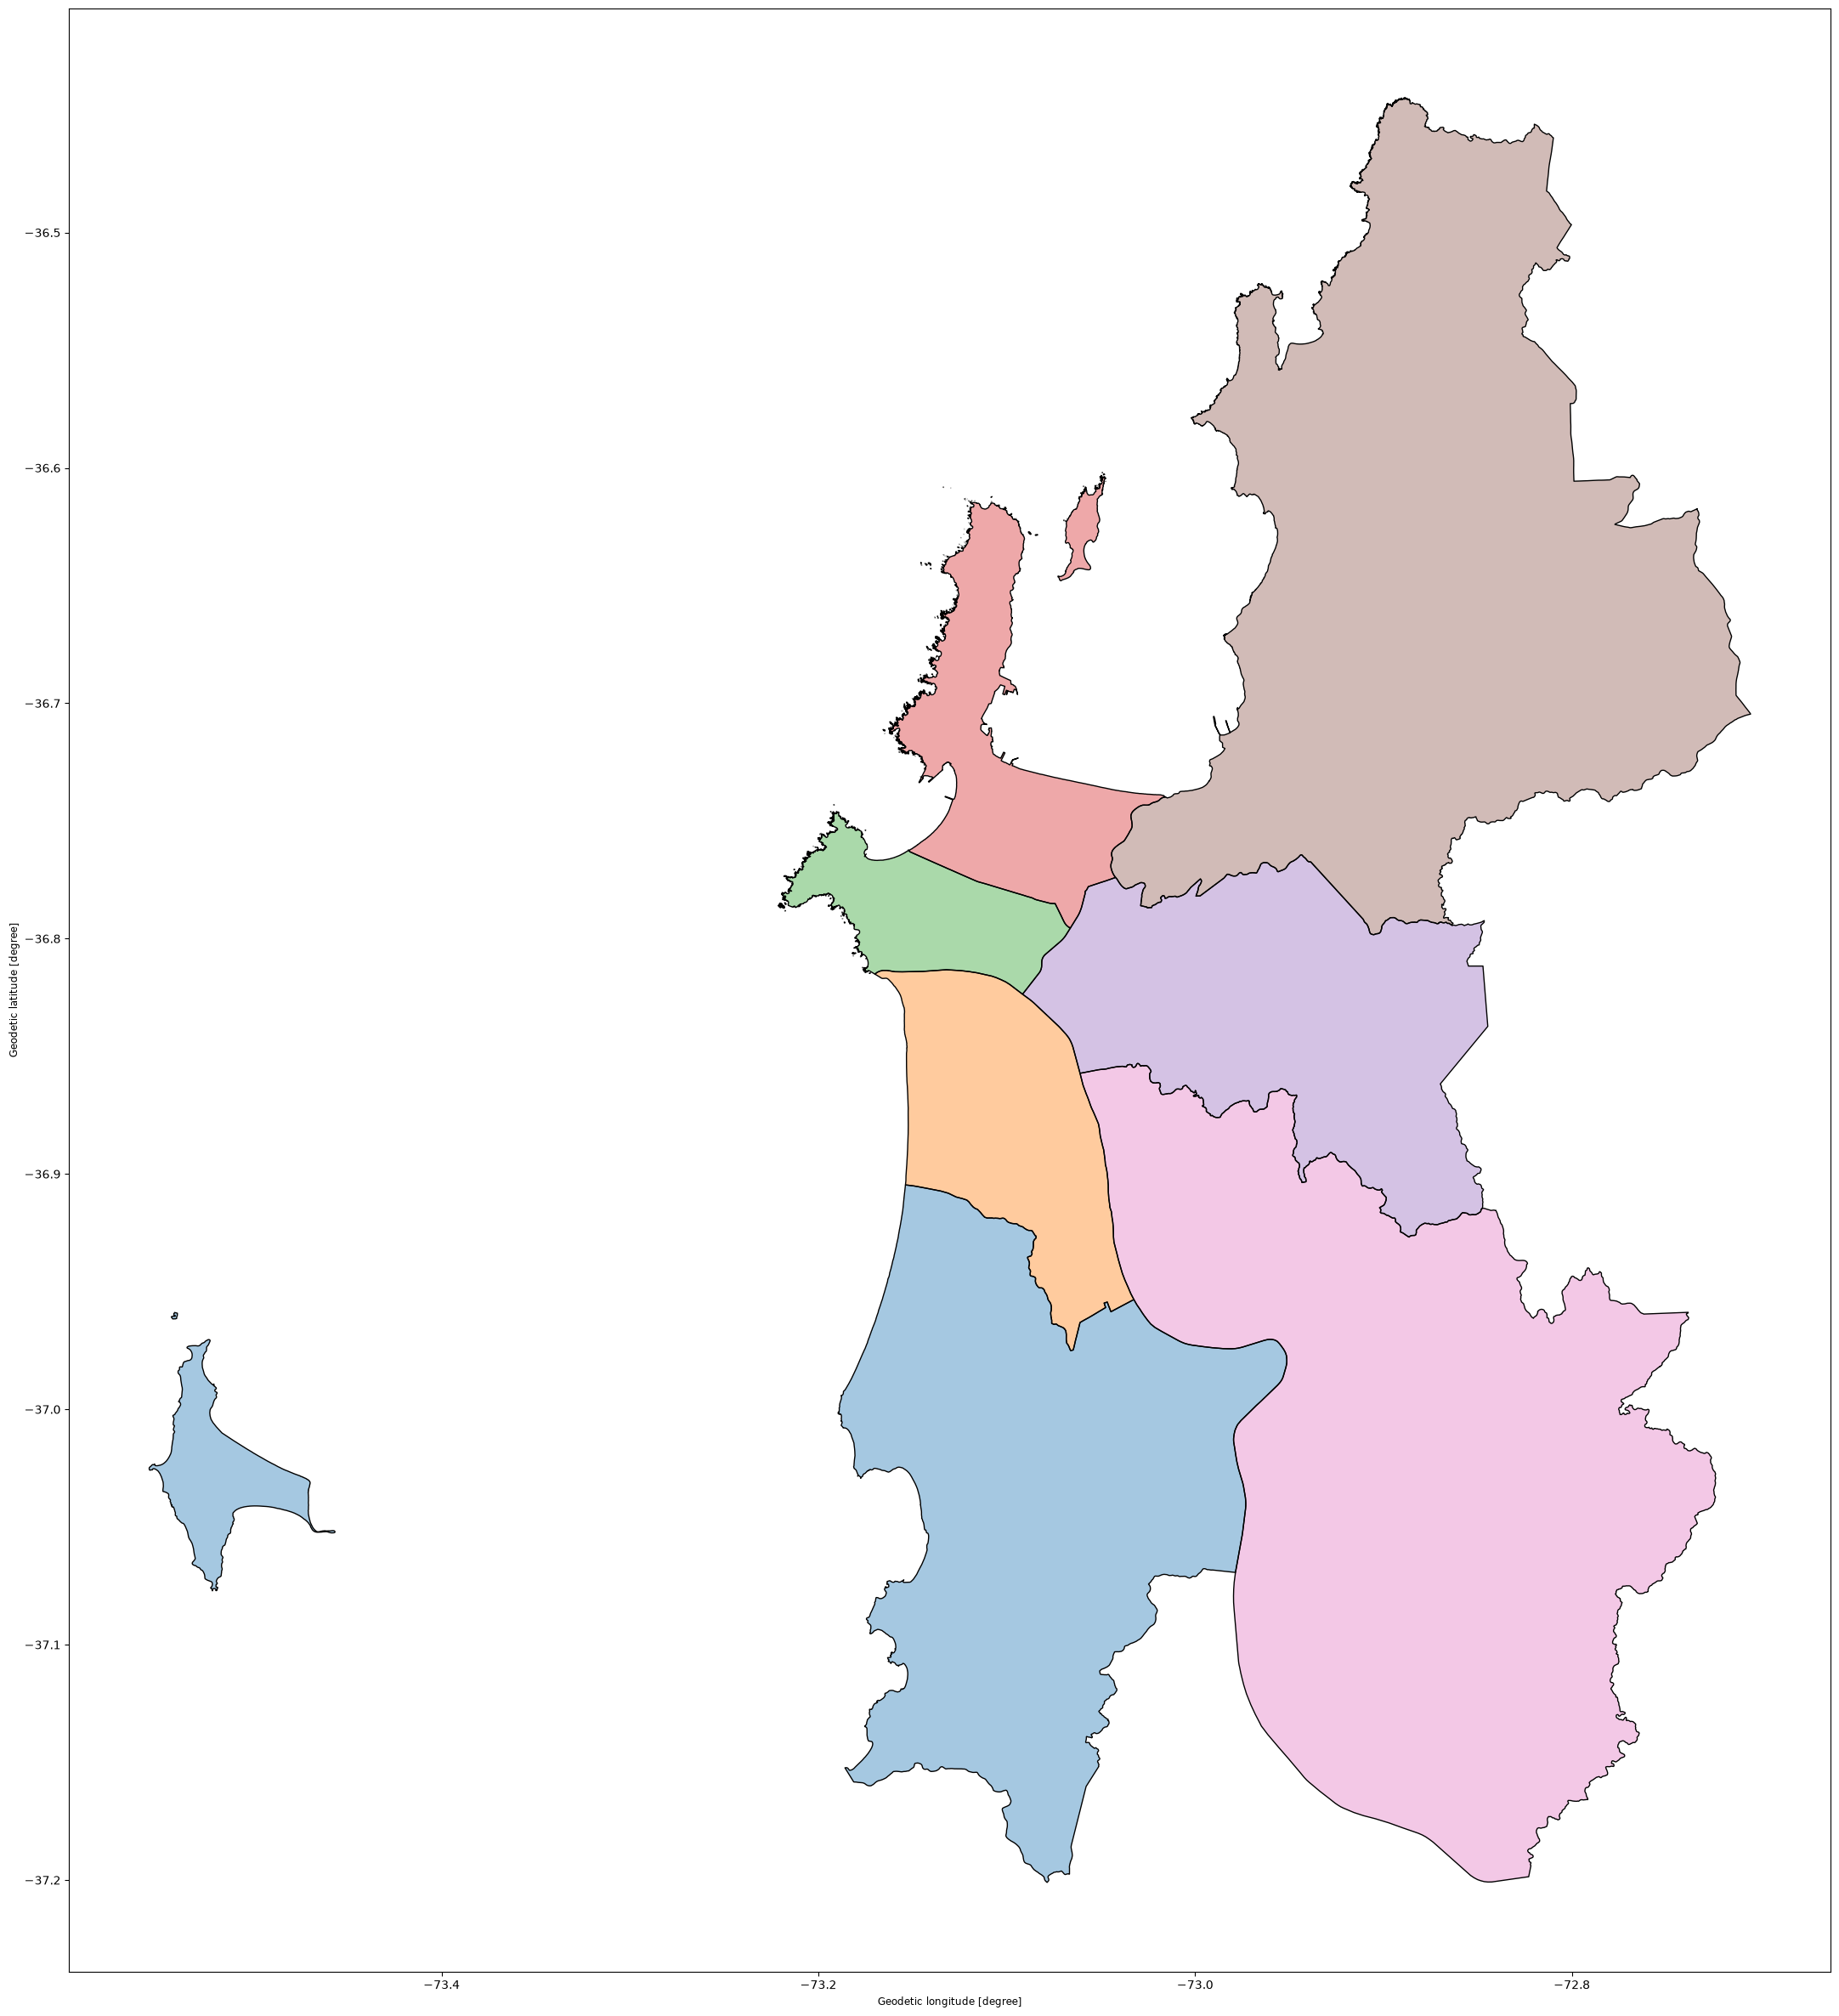

In [41]:
ax = macrozones.plot(figsize=(30,30), edgecolor="none", column="id", alpha=0.4)
macrozones.plot(ax=ax, color="none", edgecolor="black")

In [282]:
import re
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point


def parse_coord(val):
  if pd.isna(val):
    return None
  
  nums = re.findall(r"[-+]?\d*\.\d+|[-+]?\d+", str(val))

  if len(nums) >= 2:
    val1, val2 = float(nums[0]), float(nums[1])
    if abs(val1) > abs(val2):
      lon, lat = val1, val2
    else:
      lon, lat = val2, val1

    return Point(lon, lat)
  
  return None

df_clean = df.copy()

df_clean["temp_origin_geom"] = df_clean["Coord_OrigenViaje"].apply(parse_coord)
df_clean["temp_dest_geom"] = df_clean["Coord_DestinoViaje"].apply(parse_coord)

df_clean = df_clean[
    df_clean["temp_origin_geom"].notnull()
    & df_clean["temp_dest_geom"].notnull()
].copy()

origins_gdf = gpd.GeoDataFrame(
    df_clean, geometry="temp_origin_geom", crs="EPSG:4326"
)
destinations_gdf = gpd.GeoDataFrame(
    df_clean, geometry="temp_dest_geom", crs="EPSG:4326"
)

origins_gdf = origins_gdf.set_geometry("temp_origin_geom").rename_geometry("geometry")
origins_gdf = origins_gdf.drop(columns="temp_dest_geom")
destinations_gdf = destinations_gdf.set_geometry("temp_dest_geom").rename_geometry("geometry")
destinations_gdf = destinations_gdf.drop(columns="temp_origin_geom")

In [283]:
tmp = macrozones.rename(columns={"id": "macrozone"})
tmp = tmp.set_index("macrozone")

origins_gdf = origins_gdf.sjoin(tmp, "left", "intersects")
destinations_gdf = destinations_gdf.sjoin(tmp, "left", "intersects")

In [284]:
print(origins_gdf.macrozone.value_counts(), "\n")
print(destinations_gdf.macrozone.value_counts())

macrozone
4.0    4012
3.0    2773
1.0    2444
0.0    1925
2.0    1430
6.0    1340
5.0     943
Name: count, dtype: int64 

macrozone
4.0    4033
3.0    2755
1.0    2426
0.0    1924
2.0    1417
6.0    1337
5.0     912
Name: count, dtype: int64


In [285]:
pairs = list(zip(origins_gdf.macrozone, destinations_gdf.macrozone))
origins_gdf["pair"] = pairs
destinations_gdf["pair"] = pairs

origins_gdf = origins_gdf[origins_gdf.pair.apply(lambda p: not np.isnan(p[0]) and not np.isnan(p[1]))]
destinations_gdf = destinations_gdf[destinations_gdf.pair.apply(lambda p: not np.isnan(p[0]) and not np.isnan(p[1]))]

pairs

[(0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, nan),
 (nan, 0.0),
 (1.0, 4.0),
 (4.0, 1.0),
 (3.0, 3.0),
 (3.0, 3.0),
 (3.0, 4.0),
 (4.0, 4.0),
 (4.0, nan),
 (nan, 4.0),
 (4.0, 3.0),
 (3.0, 4.0),
 (4.0, 3.0),
 (3.0, 4.0),
 (4.0, 3.0),
 (4.0, 3.0),
 (3.0, 4.0),
 (4.0, 3.0),
 (3.0, 4.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (6.0, 6.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 4.0),
 (4.0, 2.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 4.0),
 (4.0, 2.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 3.0),
 (3.0, 2.0),
 (2.0, 3.0),
 (3.0, 2.0),
 (2.0, 2.0),
 (2.0, 2.0),
 (2.0, 3.0),
 (3.0, 2.0),
 (5.0, 4.0),
 (5.0, 5.0),
 (4.0, 5.0),
 (2.0, 6.0),
 (6.0, 2.0),

In [ ]:
import numpy as np

sample_count = 3000

sampled_indices = np.random.choice(origins_gdf.index, size=sample_count, replace=False)

sampled_origins = origins_gdf.loc[sampled_indices]
sampled_destinations = destinations_gdf.loc[sampled_indices]

# sampled pairs count
sampled_origins.pair.value_counts()

# 0 ([coronel, lota], macrozones)       
# 1 (san_pedro, macrozones)             
# 2 (hualpen, macrozones)               
# 3 (talcahuano, macrozones)            
# 4 (concepcion, macrozones)            
# 5 ([penco, tome], macrozones)         
# 6 ([chiguayante, hualqui], macrozones)

pair
(4.0, 4.0)    447
(3.0, 3.0)    351
(0.0, 0.0)    339
(1.0, 1.0)    288
(6.0, 6.0)    190
(5.0, 5.0)    146
(4.0, 1.0)    116
(2.0, 2.0)    100
(1.0, 4.0)     97
(4.0, 3.0)     95
(3.0, 4.0)     82
(4.0, 2.0)     77
(2.0, 4.0)     76
(3.0, 2.0)     60
(2.0, 3.0)     58
(4.0, 6.0)     40
(3.0, 1.0)     38
(5.0, 4.0)     33
(6.0, 4.0)     31
(1.0, 0.0)     30
(1.0, 3.0)     25
(4.0, 5.0)     24
(1.0, 2.0)     22
(2.0, 1.0)     21
(0.0, 1.0)     20
(3.0, 6.0)     20
(4.0, 0.0)     20
(0.0, 4.0)     17
(2.0, 6.0)     14
(0.0, 3.0)     14
(6.0, 3.0)     13
(6.0, 1.0)     12
(6.0, 2.0)     11
(3.0, 5.0)     11
(5.0, 3.0)      9
(3.0, 0.0)      9
(1.0, 5.0)      6
(2.0, 0.0)      5
(2.0, 5.0)      5
(1.0, 6.0)      5
(5.0, 1.0)      5
(5.0, 2.0)      5
(5.0, 6.0)      3
(0.0, 2.0)      3
(6.0, 0.0)      2
(0.0, 5.0)      2
(0.0, 6.0)      1
(5.0, 0.0)      1
(6.0, 5.0)      1
Name: count, dtype: int64

In [294]:
pairs_df = pd.DataFrame({"origin": sampled_origins.pair.apply(lambda v: v[0]), "destination": sampled_origins.pair.apply(lambda v: v[1])})

In [297]:
pairs_df.groupby("origin").count()

,destination
origin,
0.0,396
1.0,473
2.0,279
3.0,571
4.0,819
5.0,202
6.0,260


In [296]:
pairs_df.groupby("destination").count()

,origin
destination,
0.0,406
1.0,500
2.0,278
3.0,565
4.0,783
5.0,195
6.0,273


In [ ]:
# import numpy as np

# target_min = 80
# sampled_indices = []

# # group by pairs and sample from each
# for pair_val, group in origins_gdf.groupby("pair"):
#   available_n = len(group)

#   if available_n >= target_min:
#     # if >= target_min sample target_min
#     chosen = np.random.choice(group.index, size=target_min, replace=False)
#   else:
#     # if < target_min rows take all
#     # chosen = np.random.choice(group.index, size=target_min, replace=True)
#     chosen = group.index.values

#   sampled_indices.extend(chosen)

# # shuffle
# np.random.shuffle(sampled_indices)

# sampled_origins = origins_gdf.loc[sampled_indices]
# sampled_destinations = destinations_gdf.loc[sampled_indices]

# # sampled pairs count
# sampled_origins.pair.value_counts()

pair
(2.0, 2.0)    80
(3.0, 5.0)    80
(3.0, 4.0)    80
(2.0, 4.0)    80
(4.0, 1.0)    80
(6.0, 6.0)    80
(5.0, 4.0)    80
(1.0, 4.0)    80
(1.0, 0.0)    80
(3.0, 6.0)    80
(4.0, 6.0)    80
(4.0, 5.0)    80
(4.0, 3.0)    80
(3.0, 3.0)    80
(0.0, 4.0)    80
(6.0, 4.0)    80
(2.0, 3.0)    80
(1.0, 1.0)    80
(3.0, 0.0)    80
(1.0, 2.0)    80
(0.0, 0.0)    80
(5.0, 5.0)    80
(4.0, 2.0)    80
(6.0, 3.0)    80
(0.0, 3.0)    80
(4.0, 0.0)    80
(4.0, 4.0)    80
(2.0, 1.0)    80
(2.0, 6.0)    80
(3.0, 2.0)    80
(1.0, 3.0)    80
(6.0, 2.0)    80
(0.0, 1.0)    80
(5.0, 3.0)    80
(3.0, 1.0)    80
(6.0, 1.0)    72
(5.0, 2.0)    69
(1.0, 6.0)    57
(2.0, 5.0)    49
(2.0, 0.0)    41
(1.0, 5.0)    39
(0.0, 2.0)    39
(5.0, 1.0)    38
(6.0, 0.0)    31
(0.0, 6.0)    26
(6.0, 5.0)    22
(5.0, 0.0)    21
(5.0, 6.0)    21
(0.0, 5.0)    18
Name: count, dtype: int64

In [287]:
from shapely import linestrings

sampled_coords = sampled_origins[["pair", "macrozone", "geometry"]].merge(sampled_destinations[["macrozone", "geometry"]], suffixes=["_origin", "_destination"], left_index=True, right_index=True)
flattened_coords = sampled_coords.apply(lambda row: [[row.geometry_origin.x, row.geometry_origin.y], [row.geometry_destination.x, row.geometry_destination.y]], 1).tolist()

sampled_trips_geoms = linestrings(flattened_coords)
sampled_trips_geoms

trips_gdf = gpd.GeoDataFrame(sampled_coords, geometry=sampled_trips_geoms, crs=4326)
trips_gdf

,pair,macrozone_origin,geometry_origin,macrozone_destination,geometry_destination,geometry
14595,"(2.0, 6.0)",2.0,POINT (-73.08152 -36.80351),6.0,POINT (-73.02989 -36.93013),"LINESTRING (-73.08152 -36.80351, -73.02989 -36..."
29266,"(6.0, 6.0)",6.0,POINT (-73.02412 -36.93249),6.0,POINT (-73.01511 -36.94227),"LINESTRING (-73.02412 -36.93249, -73.01511 -36..."
45316,"(5.0, 5.0)",5.0,POINT (-72.95108 -36.63745),5.0,POINT (-72.95672 -36.59882),"LINESTRING (-72.95108 -36.63745, -72.95672 -36..."
46371,"(3.0, 2.0)",3.0,POINT (-73.09217 -36.75853),2.0,POINT (-73.06901 -36.795),"LINESTRING (-73.09217 -36.75853, -73.06901 -36..."
29677,"(1.0, 1.0)",1.0,POINT (-73.14522 -36.83743),1.0,POINT (-73.13826 -36.88554),"LINESTRING (-73.14522 -36.83743, -73.13826 -36..."
...,...,...,...,...,...,...
6230,"(0.0, 0.0)",0.0,POINT (-73.13674 -37.03564),0.0,POINT (-73.13614 -37.02851),"LINESTRING (-73.13674 -37.03564, -73.13614 -37..."
31869,"(2.0, 2.0)",2.0,POINT (-73.10874 -36.78993),2.0,POINT (-73.11293 -36.79533),"LINESTRING (-73.10874 -36.78993, -73.11293 -36..."
28972,"(2.0, 2.0)",2.0,POINT (-73.10761 -36.77902),2.0,POINT (-73.1037 -36.78296),"LINESTRING (-73.10761 -36.77902, -73.1037 -36...."
18781,"(3.0, 3.0)",3.0,POINT (-73.07691 -36.77392),3.0,POINT (-73.1456 -36.7191),"LINESTRING (-73.07691 -36.77392, -73.1456 -36...."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

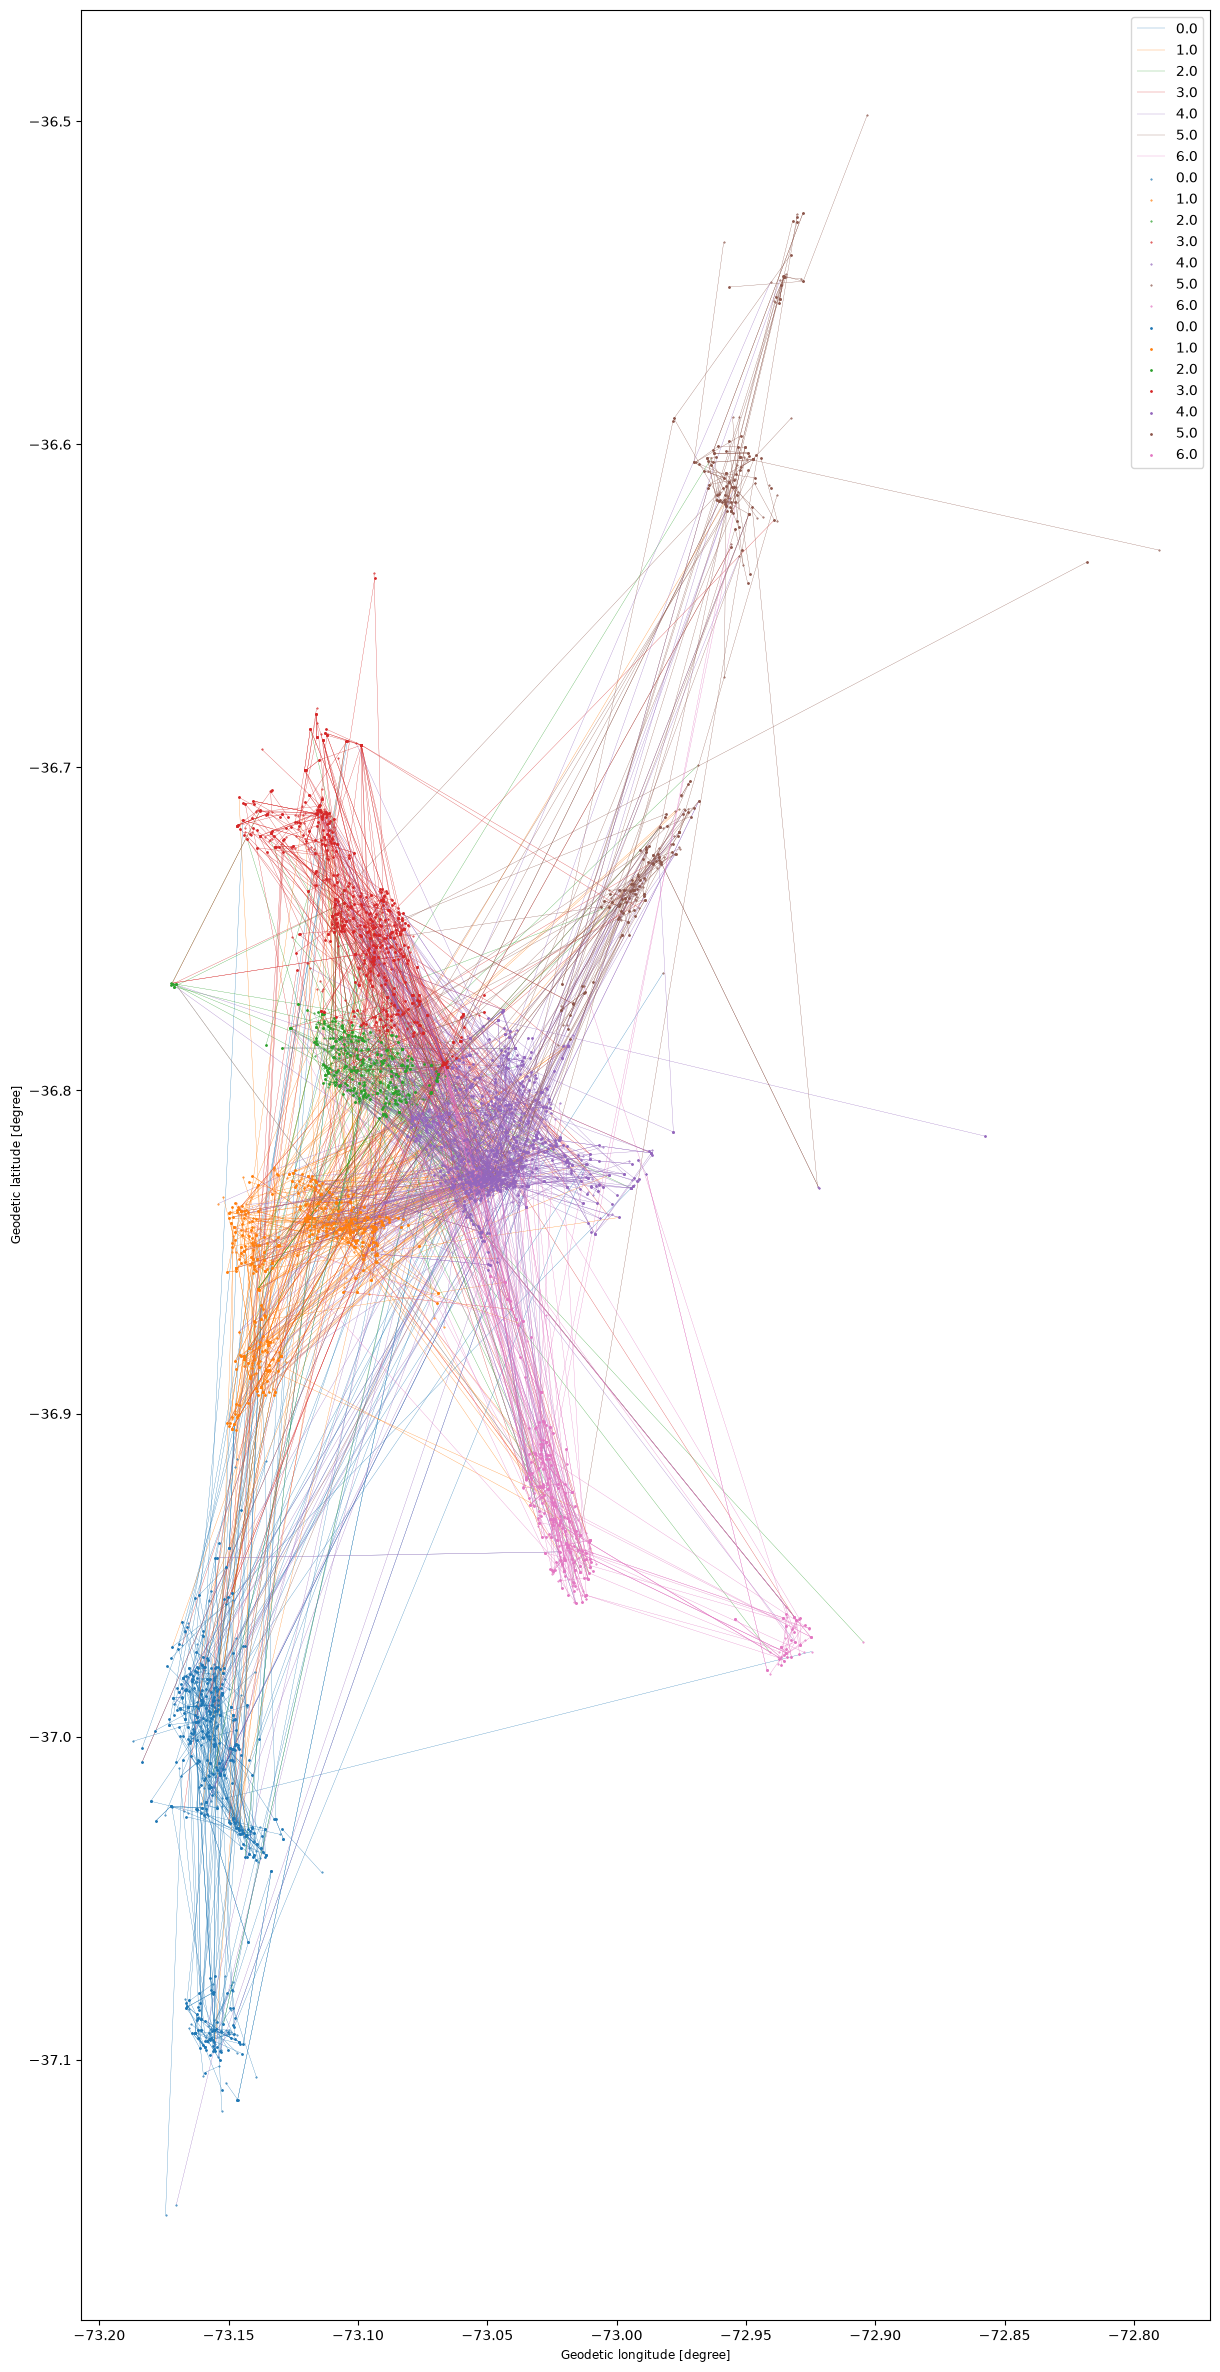

In [288]:
ax = trips_gdf.plot(figsize=(30,30), linewidth=0.2, column=trips_gdf["macrozone_destination"].astype(str), legend=False, zorder=0)
sampled_origins.plot(ax=ax, markersize=0.2, column=sampled_origins["macrozone"].astype(str), legend=False, zorder=1)
sampled_destinations.plot(ax=ax, markersize=1, column=sampled_destinations["macrozone"].astype(str), legend=True, zorder=2)